# Economic Data Analysis with Fred & Pandas
Pull The data, Visualize, discover insights... All with python/pandas!

This notebook was created as a youtube tutorial you can find on my channel [here](https://www.youtube.com/channel/UCxladMszXan-jfgzyeIMyvw).

<img src="https://miro.medium.com/proxy/1*xR4m0oOKz_jRgQU4Oge53g.jpeg" width="500" height="200" />


In [23]:
%pip install fredapi 

Note: you may need to restart the kernel to use updated packages.


In [24]:
%pip install python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import time

plt.style.use('fivethirtyeight')
pd.set_option('display.max_columns', 500)
color_pal = plt.rcParams["axes.prop_cycle"].by_key()["color"]

import os
from fredapi import Fred

fred_key = os.getenv("FRED_API_KEY")

if not fred_key:
    raise ValueError("FRED_API_KEY is not set.")

fred = Fred(api_key=fred_key)

# 1. Create The Fred Object

In [26]:
fred = Fred(api_key=fred_key)

In [42]:
states = {
 'Alabama':('AL','01'),'Alaska':('AK','02'),'Arizona':('AZ','04'),'Arkansas':('AR','05'),
 'California':('CA','06'),'Colorado':('CO','08'),'Connecticut':('CT','09'),'Delaware':('DE','10'),
 'Florida':('FL','12'),'Georgia':('GA','13'),'Hawaii':('HI','15'),'Idaho':('ID','16'),
 'Illinois':('IL','17'),'Indiana':('IN','18'),'Iowa':('IA','19'),'Kansas':('KS','20'),
 'Kentucky':('KY','21'),'Louisiana':('LA','22'),'Maine':('ME','23'),'Maryland':('MD','24'),
 'Massachusetts':('MA','25'),'Michigan':('MI','26'),'Minnesota':('MN','27'),'Mississippi':('MS','28'),
 'Missouri':('MO','29'),'Montana':('MT','30'),'Nebraska':('NE','31'),'Nevada':('NV','32'),
 'New Hampshire':('NH','33'),'New Jersey':('NJ','34'),'New Mexico':('NM','35'),'New York':('NY','36'),
 'North Carolina':('NC','37'),'North Dakota':('ND','38'),'Ohio':('OH','39'),'Oklahoma':('OK','40'),
 'Oregon':('OR','41'),'Pennsylvania':('PA','42'),'Rhode Island':('RI','44'),'South Carolina':('SC','45'),
 'South Dakota':('SD','46'),'Tennessee':('TN','47'),'Texas':('TX','48'),'Utah':('UT','49'),
 'Vermont':('VT','50'),'Virginia':('VA','51'),'Washington':('WA','53'),'West Virginia':('WV','54'),
 'Wisconsin':('WI','55'),'Wyoming':('WY','56'),
}

uemp_states = pd.concat(
    [fred.get_series(f'{abbr}UR').rename(name) for name, (abbr, fips) in states.items()],
    axis=1).dropna()

part_states = pd.concat(
    [fred.get_series(f'LBSSA{fips}').rename(name) for name, (abbr, fips) in states.items()],
    axis=1).dropna()

print(uemp_states.shape, part_states.shape)

(608, 50) (608, 50)


# 2. Search for economic data!

In [43]:
sp_search = fred.search('S&P', order_by='popularity')

In [44]:
sp_search.head()

,id,realtime_start,realtime_end,title,observation_start,observation_end,frequency,frequency_short,units,units_short,seasonal_adjustment,seasonal_adjustment_short,last_updated,popularity,notes
series id,,,,,,,,,,,,,,,
BAMLH0A0HYM2,BAMLH0A0HYM2,2026-10-26,2026-10-26,ICE BofA US High Yield Index Option-Adjusted S...,2023-10-24,2026-10-22,"Daily, Close",D,Percent,%,Not Seasonally Adjusted,NSA,2026-10-23 08:34:01-05:00,100,"Starting in April 2026, this series will only ..."
SP500,SP500,2026-10-26,2026-10-26,S&P 500,2016-10-24,2026-10-21,"Daily, Close",D,Index,Index,Not Seasonally Adjusted,NSA,2026-10-21 19:01:54-05:00,89,The observations for the S&P 500 represent the...
BAMLC0A0CM,BAMLC0A0CM,2026-10-26,2026-10-26,ICE BofA US Corporate Index Option-Adjusted Sp...,2023-10-24,2026-10-22,"Daily, Close",D,Percent,%,Not Seasonally Adjusted,NSA,2026-10-23 08:32:20-05:00,87,"Starting in April 2026, this series will only ..."
BAMLH0A0HYM2EY,BAMLH0A0HYM2EY,2026-10-26,2026-10-26,ICE BofA US High Yield Index Effective Yield,2023-10-24,2026-10-22,"Daily, Close",D,Percent,%,Not Seasonally Adjusted,NSA,2026-10-23 08:36:29-05:00,84,"Starting in April 2026, this series will only ..."
CSUSHPINSA,CSUSHPINSA,2026-10-26,2026-10-26,S&P Cotality Case-Shiller U.S. National Home P...,1987-01-01,2026-07-01,Monthly,M,Index Jan 2000=100,Index Jan 2000=100,Not Seasonally Adjusted,NSA,2026-09-30 16:00:29-05:00,83,"For more information regarding the index, plea..."


# 3. Pull Raw Data & Plot

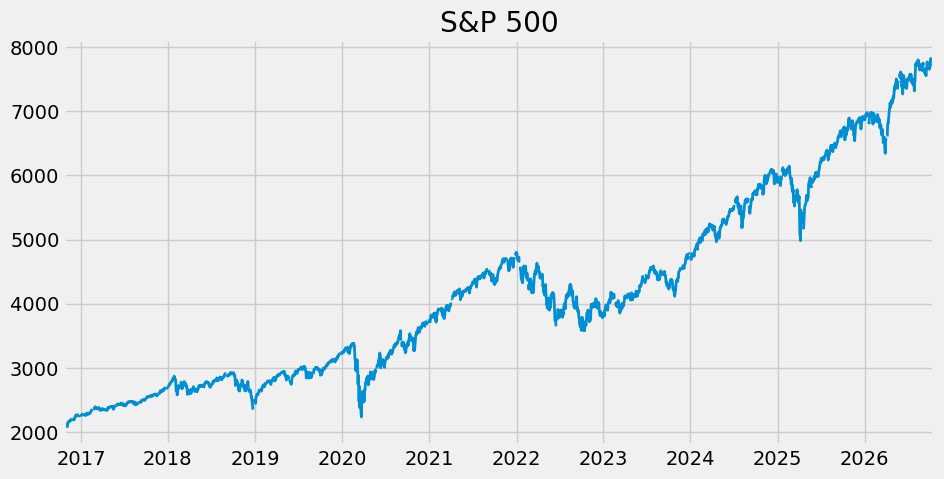

In [45]:
sp500 = fred.get_series(series_id='SP500')
sp500.plot(figsize=(10, 5), title='S&P 500', lw=2)
plt.show()

# 4. Pull and Join Multiple Data Series

In [46]:
unemp_df = fred.search('unemployment rate state', filter=('frequency','Monthly'))
unemp_df = unemp_df.query('seasonal_adjustment == "Seasonally Adjusted" and units == "Percent"')
unemp_df = unemp_df.loc[unemp_df['title'].str.contains('Unemployment Rate')]

In [48]:
all_results = []

for myid in unemp_df.index:
    results = fred.get_series(myid)
    results = results.to_frame(name=myid)
    all_results.append(results)
    time.sleep(0.1) # Don't request to fast and get blocked
uemp_results = pd.concat(all_results, axis=1)

In [49]:
cols_to_drop = []
for i in uemp_results:
    if len(i) > 4:
        cols_to_drop.append(i)
uemp_results = uemp_results.drop(columns = cols_to_drop, axis=1)

In [50]:
uemp_states = uemp_results.copy()  #.drop('UNRATE', axis=1)
uemp_states = uemp_states.dropna()
id_to_state = unemp_df['title'].str.replace('Unemployment Rate in ','').to_dict()
uemp_states.columns = [id_to_state[c] for c in uemp_states.columns]

In [51]:
# Plot States Unemployment Rate
px.line(uemp_states)

# Pull April 2020 Unemployment Rate Per State

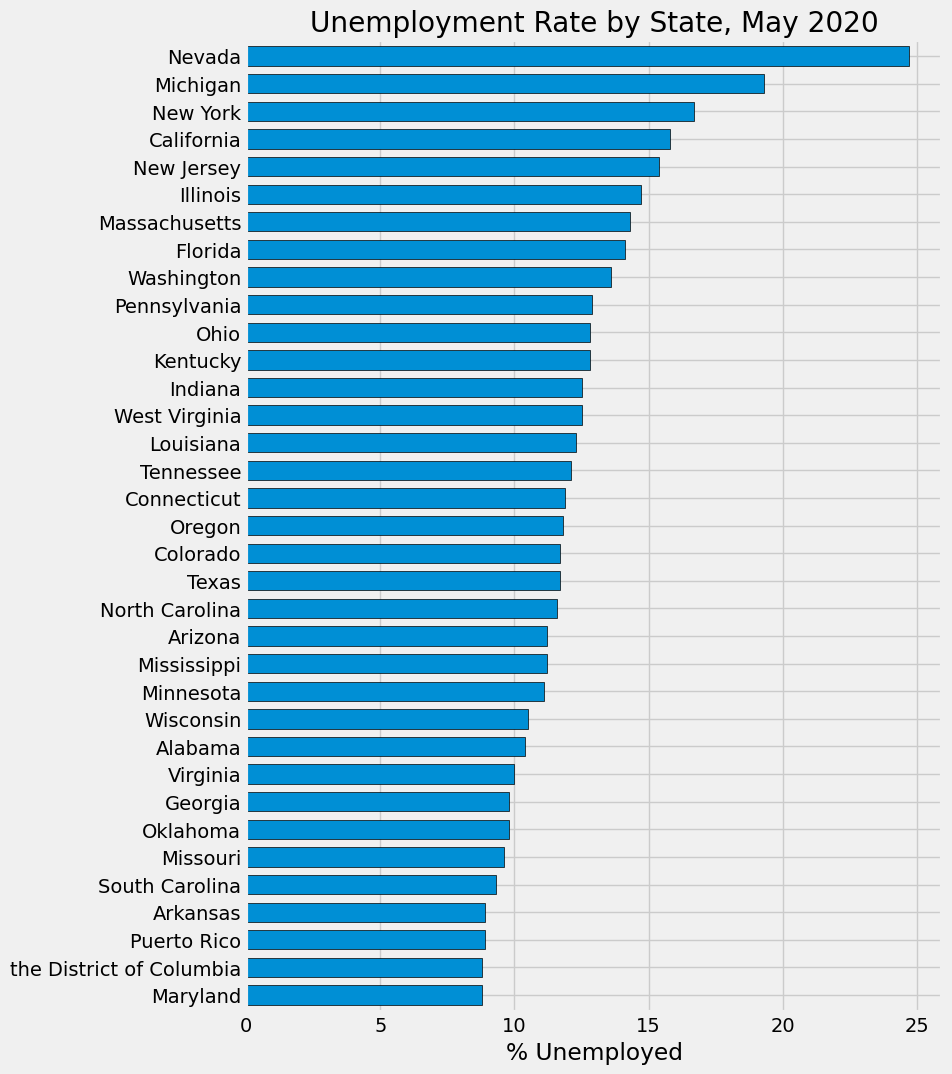

In [52]:
ax = uemp_states.loc[uemp_states.index == '2020-05-01'].T \
    .sort_values('2020-05-01') \
    .plot(kind='barh', figsize=(8, 12), width=0.7, edgecolor='black',
          title='Unemployment Rate by State, May 2020')
ax.legend().remove()
ax.set_xlabel('% Unemployed')
plt.show()

# Pull Participation Rate

In [53]:
part_df = fred.search('participation rate state', filter=('frequency','Monthly'))
part_df = part_df.query('seasonal_adjustment == "Seasonally Adjusted" and units == "Percent"')

In [54]:
part_id_to_state = part_df['title'].str.replace('Labor Force Participation Rate for ','').to_dict()

all_results = []

for myid in part_df.index:
    results = fred.get_series(myid)
    results = results.to_frame(name=myid)
    all_results.append(results)
    time.sleep(0.1) # Don't request to fast and get blocked
part_states = pd.concat(all_results, axis=1)
part_states.columns = [part_id_to_state[c] for c in part_states.columns]

# Plot Unemployment vs Participation for each state!

In [55]:
# Fix DC
uemp_states = uemp_states.rename(columns={'the District of Columbia':'District Of Columbia'})

In [56]:
print(uemp_states.shape)
print(part_states.shape)
print(uemp_states.columns.tolist())

(606, 35)
(945, 113)
['California', 'Alabama', 'Texas', 'Florida', 'Georgia', 'New York', 'Louisiana', 'Mississippi', 'Michigan', 'Illinois', 'Ohio', 'Pennsylvania', 'Missouri', 'Virginia', 'Massachusetts', 'New Jersey', 'North Carolina', 'Wisconsin', 'Oregon', 'Tennessee', 'Minnesota', 'Kentucky', 'Washington', 'District Of Columbia', 'Arizona', 'Colorado', 'Puerto Rico', 'Nevada', 'South Carolina', 'Indiana', 'West Virginia', 'Connecticut', 'Oklahoma', 'Arkansas', 'Maryland']


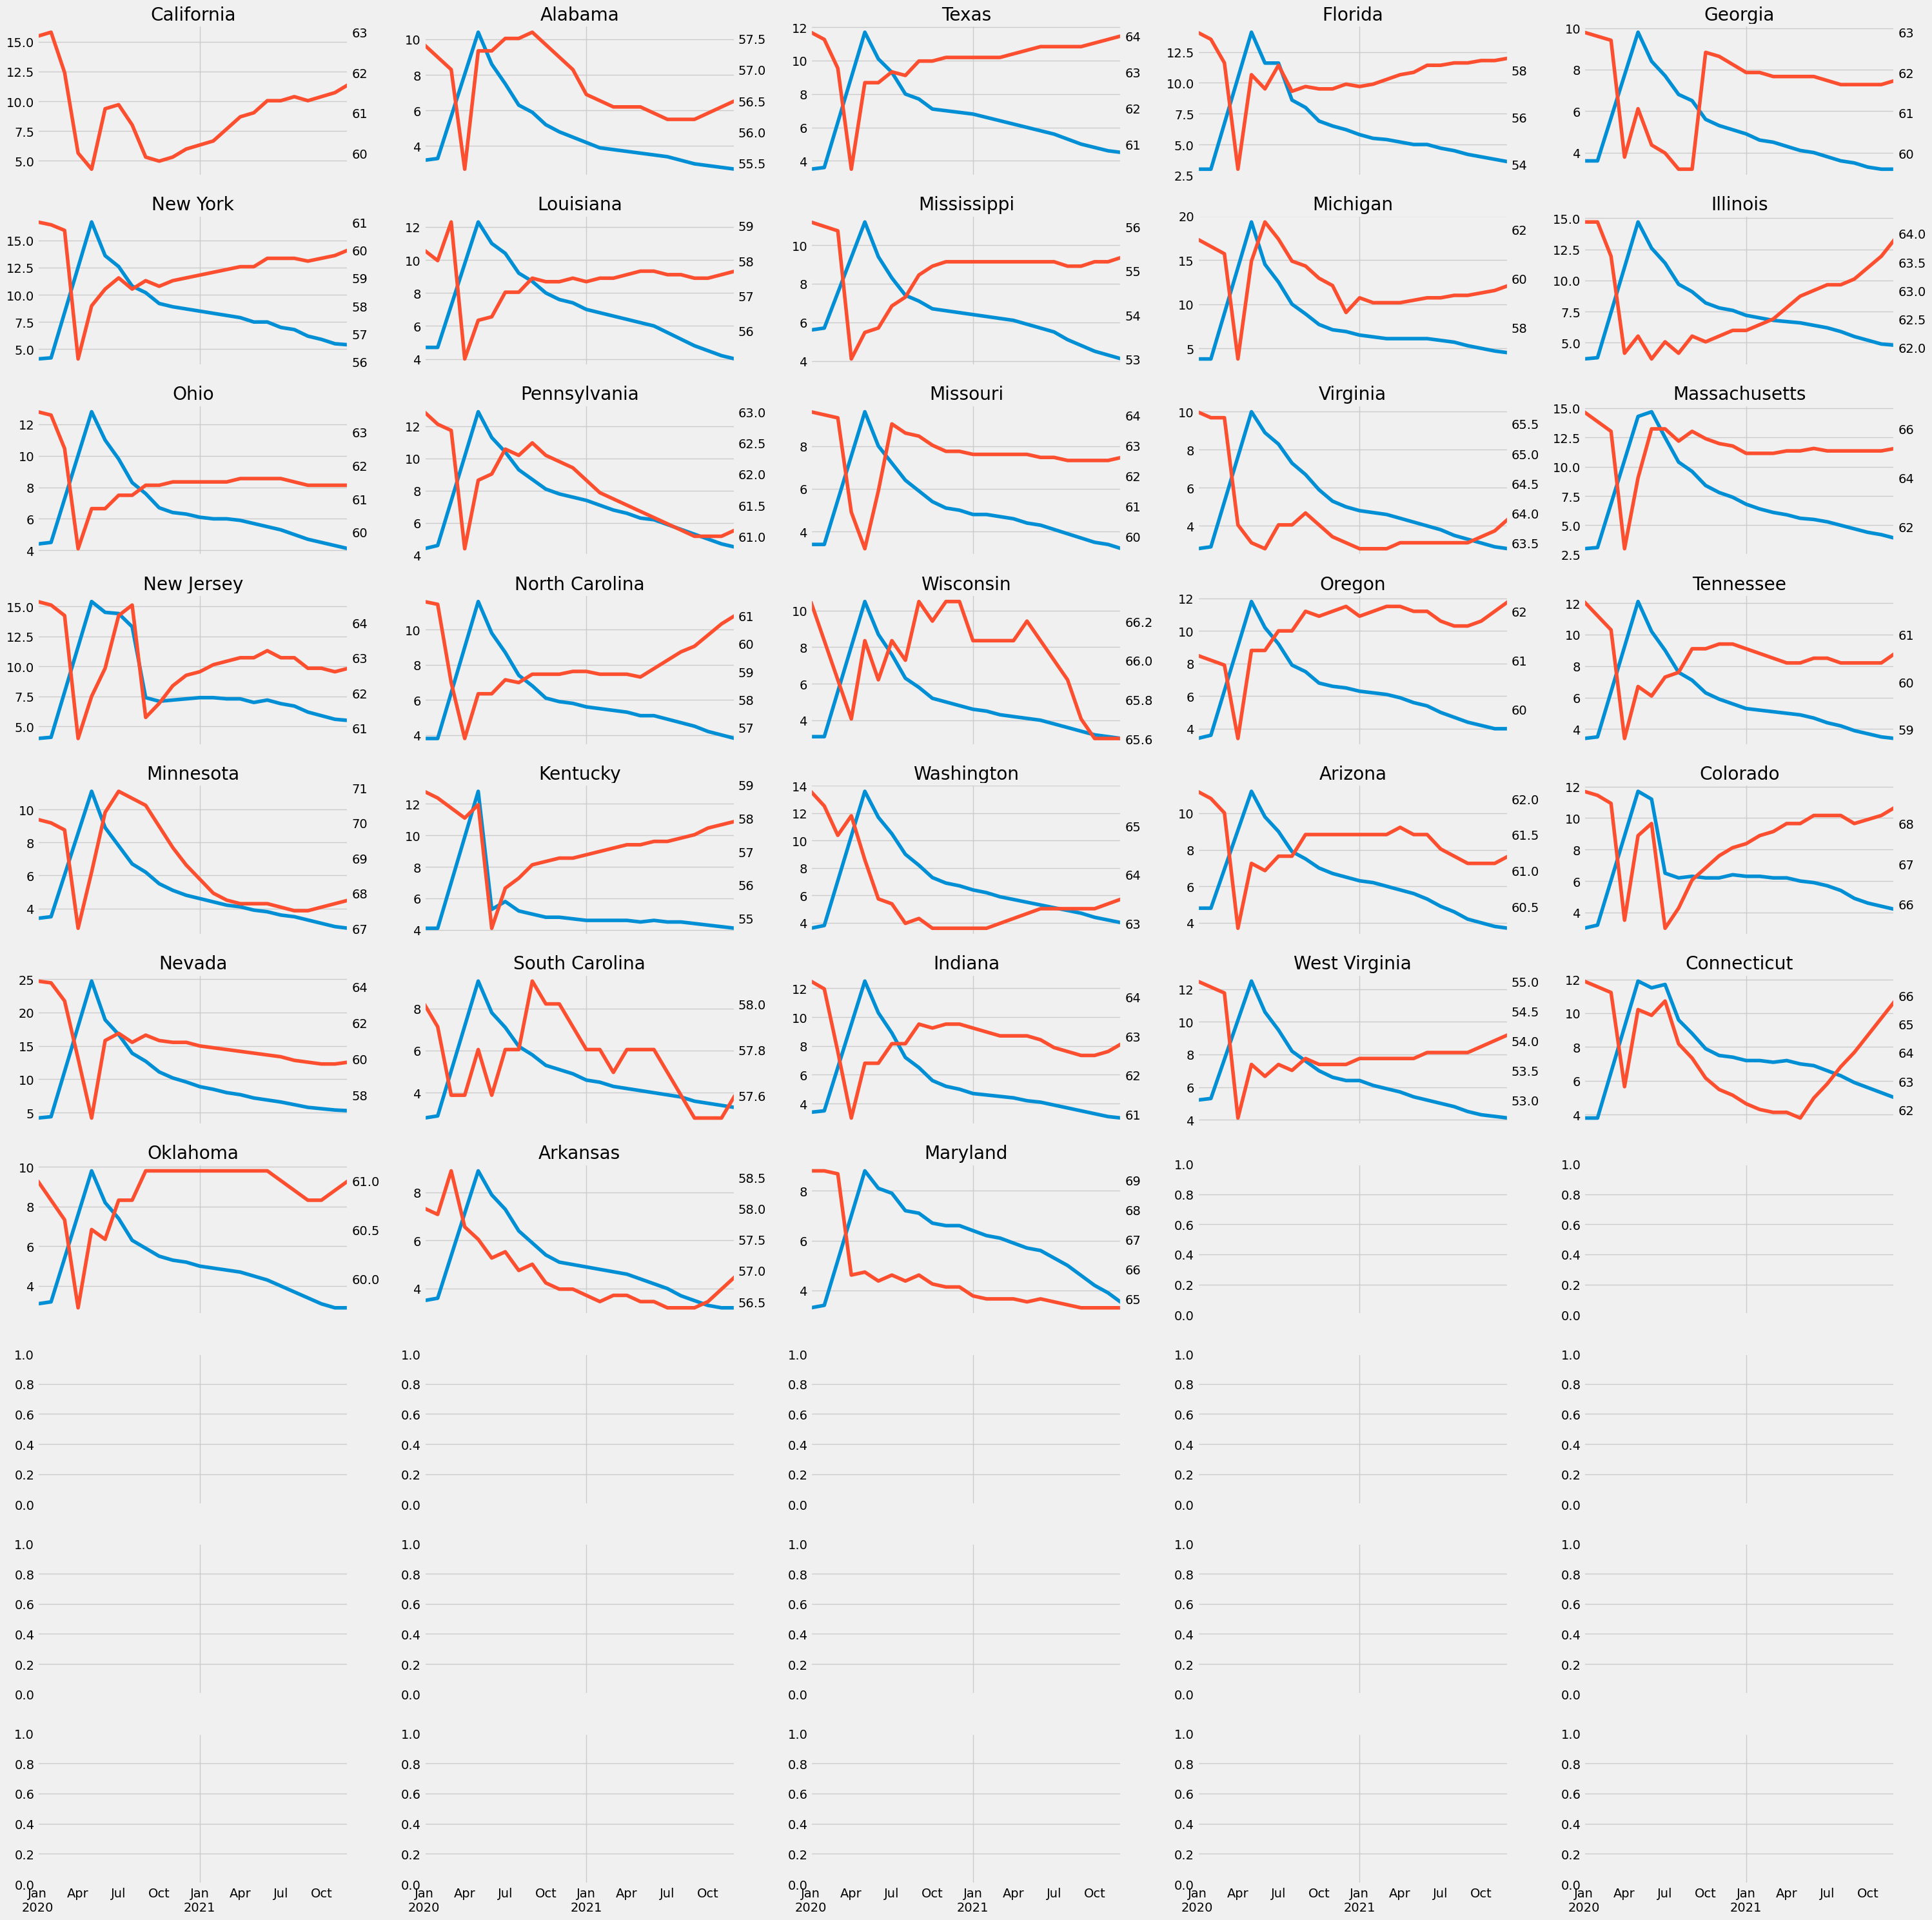

In [ ]:
fig, axs = plt.subplots(10, 5, figsize=(30, 30), sharex=True)
axs = axs.flatten()

i = 0
for state in uemp_states.columns:
    if state in ["District Of Columbia","Puerto Rico"]:
        continue
    ax2 = axs[i].twinx()
    uemp_states.query('index >= 2020 and index < 2022')[state] \
        .plot(ax=axs[i], label='Unemployment')
    part_states.query('index >= 2020 and index < 2022')[state] \
        .plot(ax=ax2, label='Participation', color=color_pal[1])
    ax2.grid(False)
    axs[i].set_title(state)
    i += 1
plt.tight_layout()

#plt.show()

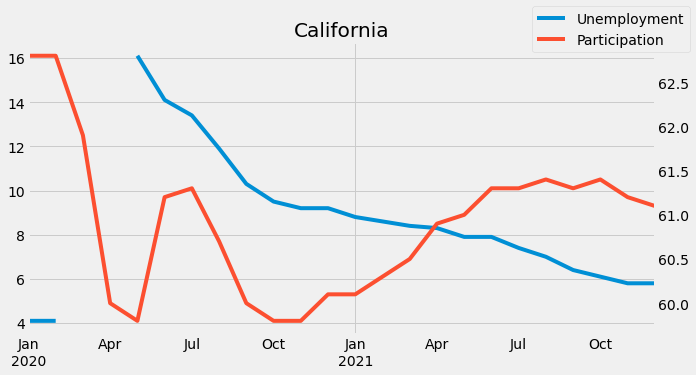

In [ ]:
state = 'California'
fig, ax = plt.subplots(figsize=(10, 5), sharex=True)
ax2 = ax.twinx()
uemp_states2 = uemp_states.asfreq('MS')
l1 = uemp_states2.query('index >= 2020 and index < 2022')[state] \
    .plot(ax=ax, label='Unemployment')
l2 = part_states.dropna().query('index >= 2020 and index < 2022')[state] \
    .plot(ax=ax2, label='Participation', color=color_pal[1])
ax2.grid(False)
ax.set_title(state)
fig.legend(labels=['Unemployment','Participation'])
plt.show()

# The End

Now you explore!